# aufgabe 2 · objekterkennung auf der straße

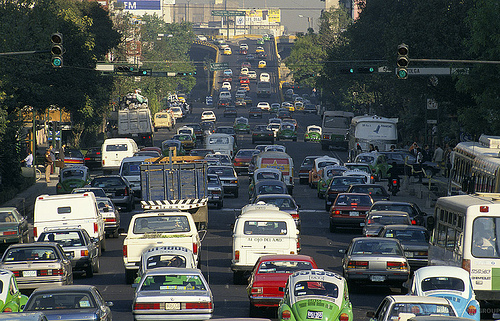

In [10]:
from collections import Counter
from time import perf_counter

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
import yaml
from IPython.display import display
from matplotlib.patches import Patch, Rectangle
from matplotlib_inline.backend_inline import set_matplotlib_formats
from PIL import Image
from ultralytics import YOLO
from src.detect_road_objects import CLASSES, EXAMPLE, TRAIN_IMAGES, WEIGHTS

set_matplotlib_formats("jpeg")
WEIGHTS.parent.mkdir(exist_ok=True)
model = YOLO(WEIGHTS)
class_ids = [i for i, name in model.names.items() if name in CLASSES]
settings = dict(device="cpu", imgsz=640, classes=class_ids, verbose=False, save=False)

with Image.open(EXAMPLE) as photo:
    pixels = photo.convert("RGB")
width, height = pixels.size
display(pixels)

## eine erkennung lesen

bei der inferenz gibt das modell klasse, konfidenz und box aus. der ausschnitt zeigt die box mit der höchsten konfidenz.

{'name': 'car',
 'class': 2,
 'confidence': 0.84956,
 'box': {'x1': 131.25342, 'y1': 266.52887, 'x2': 215.08687, 'y2': 321.0}}

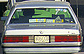

In [11]:
result = model.predict(EXAMPLE, conf=0.25, **settings)[0]
predictions = result.summary()
if predictions:
    first = max(predictions, key=lambda obj: obj["confidence"])
    display(first)
    box = first["box"]
    display(pixels.crop((box["x1"], box["y1"], box["x2"], box["y2"])))

## vorhersagen mit coco vergleichen

links stehen die vorhersagen, rechts die annotationen. erhöhe `min_confidence` auf 0.60 und vergleiche die boxen.

In [12]:
dataset = EXAMPLE.parents[2]
class_names = yaml.safe_load((dataset / "dataset.yaml").read_text())["names"]
annotations = []
label_file = dataset / "labels/train" / f"{EXAMPLE.stem}.txt"
for line in label_file.read_text().splitlines():
    class_id, cx, cy, w, h = map(float, line.split())
    annotations.append({
        "name": class_names[int(class_id)],
        "box": {"x1": (cx - w/2) * width, "y1": (cy - h/2) * height,
                "x2": (cx + w/2) * width, "y2": (cy + h/2) * height},
    })

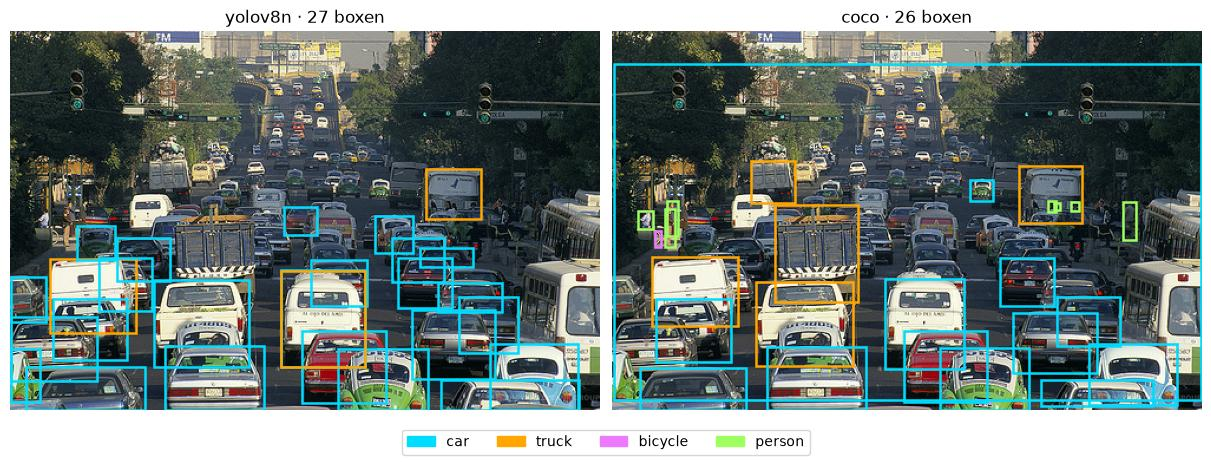

In [13]:
min_confidence = 0.25
assert 0.25 <= min_confidence <= 1, "wähle einen wert zwischen 0.25 und 1."
visible = [obj for obj in predictions if obj["confidence"] >= min_confidence]
colors = {"car": "#00dcff", "truck": "#ffa600", "bicycle": "#ed79ff", "person": "#9fff61"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, objects, title in zip(axes, [visible, annotations], ["yolov8n", "coco"]):
    ax.imshow(pixels)
    for obj in objects:
        b = obj["box"]
        ax.add_patch(Rectangle((b["x1"], b["y1"]), b["x2"] - b["x1"], b["y2"] - b["y1"],
                               fill=False, edgecolor=colors[obj["name"]], linewidth=1.8))
    ax.set_title(f"{title} · {len(objects)} boxen")
    ax.axis("off")
fig.legend(handles=[Patch(color=colors[c], label=c) for c in CLASSES],
           loc="outside lower center", ncols=4)
plt.show()

In [14]:
counts = pd.DataFrame({
    "yolov8n": Counter(obj["name"] for obj in visible),
    "coco": Counter(obj["name"] for obj in annotations),
}, index=list(CLASSES)).fillna(0).astype(int)
counts["differenz"] = counts["yolov8n"] - counts["coco"]
display(counts)

,yolov8n,coco,differenz
car,24,13,11
truck,3,5,-2
bicycle,0,1,-1
person,0,7,-7


## batchgrößen testen

ein batch bündelt mehrere bilder in einem aufruf. wir laden alle 50 bilder in den speicher und wärmen jede batchgröße auf. dann messen wir je vier durchläufe mit 640 × 640 pixeln.

In [15]:
paths = sorted(TRAIN_IMAGES.glob("*.jpg"))
assert len(paths) == 50, "bitte zuerst den coco-export wiederherstellen."
frames = [cv2.imread(str(path)) for path in paths]
assert all(frame is not None for frame in frames)

batch_sizes = [1, 2, 5, 10]
benchmark = dict(settings, rect=False, conf=0.25)
for size in batch_sizes:
    model.predict(frames[:size], **benchmark)

print(f"cpu · {torch.get_num_threads()} torch-threads")

cpu · 8 torch-threads


In [16]:
measurements = []
for repeat in range(len(batch_sizes)):
    order = batch_sizes[repeat:] + batch_sizes[:repeat]
    for size in order:
        for start in range(0, len(frames), size):
            batch = frames[start:start + size]
            begin = perf_counter()
            results = model.predict(batch, **benchmark)
            elapsed = perf_counter() - begin
            assert len(results) == len(batch) == size
            measurements.append({
                "batch": size, "runde": repeat + 1, "bilder": len(batch),
                "aufruf_ms": 1000 * elapsed,
                "netz_ms_pro_bild": results[0].speed["inference"],
            })

latenz misst hier die zeit vom aufruf von `predict()` bis die ergebnisse des ganzen batches vorliegen. das einlesen der bilder und das warten auf weitere kamerabilder liegen außerhalb der messung. p50 ist der median. p95 zeigt, wie lange rund 95 % der aufrufe höchstens dauern.

In [17]:
timings = pd.DataFrame(measurements)
by_size = timings.groupby("batch")
summary = by_size.agg(aufrufe=("bilder", "size"), bilder=("bilder", "sum"),
                      p50_ms=("aufruf_ms", "median"),
                      p95_ms=("aufruf_ms", lambda s: s.quantile(0.95)),
                      netz_ms_pro_bild=("netz_ms_pro_bild", "mean"))
summary["gesamt_ms_pro_bild"] = by_size["aufruf_ms"].sum() / summary["bilder"]
summary["bilder_pro_s"] = 1000 / summary["gesamt_ms_pro_bild"]
assert (summary["bilder"] == 200).all()
display(summary.round(2))

,aufrufe,bilder,p50_ms,p95_ms,netz_ms_pro_bild,gesamt_ms_pro_bild,bilder_pro_s
batch,,,,,,,
1,200,200,43.62,53.89,44.34,45.59,21.94
2,100,200,79.37,93.67,39.99,40.91,24.44
5,40,200,150.95,155.68,29.50,30.26,33.05
10,20,200,284.77,315.72,28.40,29.12,34.34


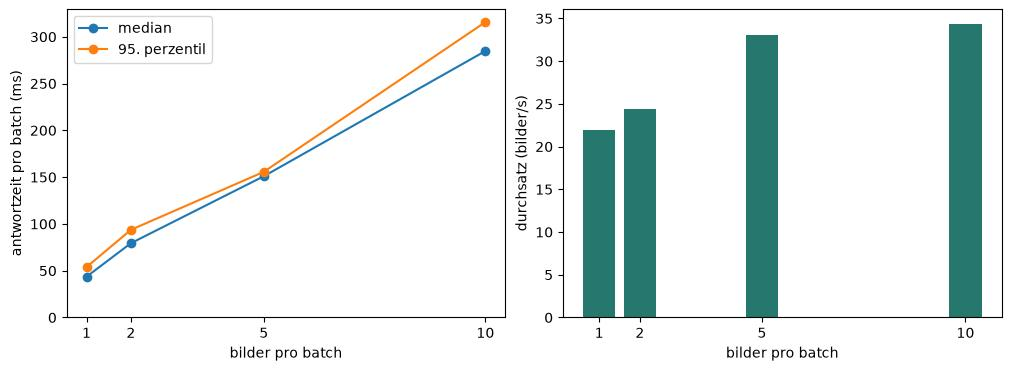

kürzeste mediane antwortzeit: batch 1 (43.6 ms).
höchster gemessener durchsatz: batch 10 (34.3 bilder/s).


In [18]:
fig, (latency, throughput) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for col, label in [("p50_ms", "median"), ("p95_ms", "95. perzentil")]:
    latency.plot(summary.index, summary[col], marker="o", label=label)
latency.set_ylabel("antwortzeit pro batch (ms)")
latency.legend()
throughput.bar(summary.index, summary["bilder_pro_s"], color="#26776e")
throughput.set_ylabel("durchsatz (bilder/s)")
for ax in (latency, throughput):
    ax.set_xlabel("bilder pro batch")
    ax.set_xticks(batch_sizes)
    ax.set_ylim(bottom=0)
plt.show()

quick = summary.p50_ms.idxmin()
fast = summary.bilder_pro_s.idxmax()
print(f"kürzeste mediane antwortzeit: batch {quick} ({summary.loc[quick, 'p50_ms']:.1f} ms).")
print(f"höchster gemessener durchsatz: batch {fast} ({summary.loc[fast, 'bilder_pro_s']:.1f} bilder/s).")

## takeaway

- für ein einzelnes kamerabild reagiert batch 1 im gezeigten lauf am schnellsten: nach 43,6 ms liegt typischerweise ein ergebnis vor, nach 53,9 ms bei rund 95 % der aufrufe.
- für einen bilderordner zählt der durchsatz. batch 5 schafft 33,1 bilder/s, batch 10 schafft 34,3 bilder/s. für diesen kleinen zugewinn steigt die mediane wartezeit pro batch von 151 auf 285 ms. die 29,1 ms pro bild bei batch 10 sind ein durchschnitt über zehn gemeinsam verarbeitete bilder.
- beim straßenbild zählt das modell 24 autos, coco enthält 13. ob einzelne autos doppelt erkannt wurden oder boxen fehlen, siehst du erst beim vergleich ihrer positionen.